# STEAM-GAME-PROJECT — Phân tích dữ liệu Non-ML: Câu hỏi nghiên cứu 2

Notebook này triển khai câu hỏi nghiên cứu 2 (Q2) của nhóm theo chuẩn mực khoa học dữ liệu: phân tích mối liên hệ giữa quy mô sở hữu, tuổi đời game và thể loại với mức độ tham gia đánh giá, cũng như mối liên hệ giữa số lượt đánh giá và tỷ lệ tích cực. Dữ liệu sử dụng từ Steam snapshot tháng 03/2025. Các kết quả chỉ mô tả mối liên hệ thống kê quan sát được, không suy diễn quan hệ nhân quả.

---

# 3.3. Xây dựng câu hỏi nghiên cứu

## 3.3.2. RQ2 — Quy mô đánh giá và tỷ lệ tích cực

### 1. Câu hỏi nghiên cứu

> “Những yếu tố về quy mô người sở hữu, tuổi đời và thể loại game có mối liên hệ như thế nào với mức độ tham gia đánh giá của người chơi, và mối quan hệ giữa mức độ tham gia đánh giá với tỷ lệ đánh giá tích cực có thay đổi giữa các thể loại hay không; liệu những mối quan hệ này có duy trì khi kiểm soát các yếu tố liên quan và thay đổi cách xử lý ngoại lệ?”

### 2. Động cơ nghiên cứu

Số lượt đánh giá phản ánh mức độ người chơi sẵn sàng để lại phản hồi, còn tỷ lệ tích cực tóm tắt chiều hướng hài lòng của cộng đồng. Phân tích giúp làm rõ hai chỉ số này tương tác thế nào theo quy mô sở hữu, tuổi game và thể loại, từ đó hỗ trợ quản lý kỳ vọng cộng đồng và định vị sản phẩm.

**Bên quan tâm:** Nhà phát triển, nhà phát hành và nhóm vận hành/chăm sóc cộng đồng.

**Giá trị thực tiễn:** Giúp so sánh chuẩn mức độ tương tác giữa các thể loại sau khi đã kiểm soát quy mô sở hữu và tuổi đời game; không suy diễn quan hệ nhân quả.

### 3. Thuộc tính sử dụng

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` | Chính — Kaggle CSV | Định danh game và đơn vị lấy mẫu. |
| `num_reviews_total` | Chính — Kaggle CSV | Số lượt đánh giá; giá trị `-1` được xác định là sentinel (không có đánh giá hợp lệ). |
| `pct_pos_total` | Chính — Kaggle CSV | Tỷ lệ đánh giá tích cực; `-1` là sentinel. |
| `estimated_owners`, `release_date` | Chính — Kaggle CSV | Quy mô sở hữu ước tính và tuổi game dùng làm biến giải thích/kiểm soát. |
| `genres` | Chính — Kaggle CSV | Nhóm phân tầng/so sánh; game có thể thuộc nhiều thể loại. |

### 4. Giả thuyết nghiên cứu

- **H1:** Số lượt đánh giá có mối liên hệ đồng biến với quy mô sở hữu ước tính và tuổi game sau khi kiểm soát thể loại.
- **H2:** Mối liên hệ giữa số lượt đánh giá và tỷ lệ đánh giá tích cực khác nhau đáng kể giữa các thể loại sau khi kiểm soát quy mô sở hữu và tuổi game.
- **H3:** Các mối liên hệ chính vẫn duy trì hướng tác động và độ lớn khi loại bỏ 1% game có số lượt đánh giá cao nhất (kiểm tra độ bền với blockbuster ngoại lệ).

### 5. Tiêu chí chiều sâu phân tích — dự kiến

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D2 — Tái cấu trúc / Thời gian** | Tách danh sách `genres` thành bảng phụ để tóm tắt theo thể loại; giữ khóa game để một game không bị tính lặp trong mô hình tổng thể. | Phân tích nhóm thể loại mà vẫn xác định đúng đơn vị quan sát. |
| **D3 — Biến dẫn xuất** | Dùng `log1p(num_reviews_total)` và `log1p(owner_midpoint)` để giảm lệch phải; tính `game_age` đến 31/03/2025. | Đưa biến đếm và quy mô sở hữu lệch mạnh về thang dễ mô hình hóa. |
| **D4 — Kiểm soát yếu tố gây nhiễu** | Hồi quy OLS ở cấp game, đồng thời đưa quy mô sở hữu, tuổi game và cờ thể loại vào mô hình; mô hình thứ hai thêm tương tác giữa log lượt đánh giá và thể loại. | Ước lượng mối liên hệ có điều kiện; không diễn giải là nhân quả. |
| **D5 — Định lượng độ bất định** | Hồi quy OLS với sai số chuẩn vững HC3 và khoảng tin cậy 95%; kiểm định Wald cho tương tác. | Đo lường độ lớn và độ bất định, có xét phương sai sai số thay đổi. |
| **D6 — Kiểm tra độ bền vững** | Lặp lại toàn bộ mô hình sau khi loại bỏ 1% game có số lượt đánh giá cao nhất; đối chiếu hướng và độ lớn hệ số. | Đánh giá tính nhạy cảm trước các tựa game ngoại lệ cực lớn. |

### 6. Giới hạn nghiên cứu

Tập dữ liệu có 89.618 game nhưng có tới 36.419 game mang giá trị sentinel `-1` ở `num_reviews_total` và `pct_pos_total`, do đó phân tích chỉ thực hiện trên 53.199 game có đủ chỉ số hợp lệ. `num_reviews_total` không khớp `positive + negative` ở phần lớn dòng nên giữ nguyên trường tổng hợp từ nguồn. `estimated_owners` là khoảng ước tính. Kết quả phản ánh mối liên hệ ở cấp tựa game, không mô tả hành vi của từng người chơi cụ thể.

# 3.4. Phân tích dữ liệu Non-ML


## 3.4.2. Phân tích Câu hỏi nghiên cứu 2: Lượt đánh giá và tỷ lệ tích cực (RQ2)

### 1. Mục tiêu nghiên cứu

Câu hỏi nghiên cứu: **Những yếu tố về quy mô người sở hữu, tuổi đời và thể loại game có mối liên hệ như thế nào với mức độ tham gia đánh giá của người chơi, và mối quan hệ giữa mức độ tham gia đánh giá với tỷ lệ đánh giá tích cực có thay đổi giữa các thể loại hay không; liệu những mối quan hệ này có duy trì khi kiểm soát các yếu tố liên quan và thay đổi cách xử lý ngoại lệ?**

### 2. Chuẩn bị dữ liệu

Chỉ giữ các game có cả `num_reviews_total` và `pct_pos_total` hợp lệ. Giá trị `-1` là sentinel, không chuyển thành 0.

#### Thuộc tính sử dụng

| Thuộc tính | Nguồn dữ liệu | Vai trò trong phân tích |
|---|---|---|
| `appid` | CSV chính | Định danh game và đơn vị phân tích. |
| `num_reviews_total` | CSV chính | Số lượt đánh giá; giá trị `-1` không phải số đếm hợp lệ. |
| `pct_pos_total` | CSV chính | Tỷ lệ đánh giá tích cực; giá trị `-1` không phải tỷ lệ hợp lệ. |
| `estimated_owners`, `release_date` | CSV chính | Quy mô sở hữu ước tính và tuổi game dùng làm yếu tố giải thích/kiểm soát. |
| `genres` | CSV chính | Nhóm thể loại; một game có thể thuộc nhiều nhóm. |

#### Cách phân tích

Mô hình 1 ước lượng số lượt đánh giá theo quy mô sở hữu, tuổi game và thể loại. Mô hình 2 ước lượng tỷ lệ tích cực theo lượt đánh giá, các biến kiểm soát và tương tác với thể loại.

#### Tiêu chí chiều sâu

| Tiêu chí | Phương pháp dự kiến | Mục tiêu |
|---|---|---|
| **D2 – Tái cấu trúc / Thời gian** | Tách `genres` thành bảng phụ để tóm tắt theo thể loại; giữ khóa game để một game không bị tính lặp trong mô hình tổng thể. | So sánh thể loại nhưng giữ đúng đơn vị phân tích. |
| **D3 – Biến dẫn xuất** | Dùng `log1p(num_reviews_total)` và `log1p(owner_midpoint)`; tính `game_age` đến 31/03/2025. | Giảm lệch phải ở biến đếm và quy mô sở hữu. |
| **D4 – Yếu tố liên quan** | Hồi quy ở cấp game, đồng thời đưa quy mô sở hữu, tuổi game và thể loại vào mô hình; mô hình tỷ lệ tích cực thêm tương tác giữa log lượt đánh giá và thể loại. | Ước lượng mối liên hệ có điều kiện, không diễn giải là nhân quả. |
| **D5 – Định lượng độ bất định** | OLS với sai số chuẩn HC3 và khoảng tin cậy 95%; báo cỡ mẫu và hệ số. | Thể hiện độ lớn và mức bất định, có xét phương sai sai số không đồng đều. |
| **D6 – Kiểm tra độ bền** | Lặp lại mô hình sau khi giới hạn ở 99% giá trị `num_reviews_total` thấp hơn. | Kiểm tra kết quả có bị chi phối bởi một số game có lượng đánh giá rất lớn hay không. |

#### Quy tắc xử lý

CSV có 89.618 game. `num_reviews_total` và `pct_pos_total` cùng được ghi `-1` ở 36.419 game. Đây không phải số đếm hay tỷ lệ hợp lệ, nên loại các dòng này khỏi mô hình, không đổi `-1` thành 0. `num_reviews_total` không khớp `positive + negative` ở phần lớn dòng; vì vậy dùng trực tiếp hai trường tổng hợp và không tự dựng lại tỷ lệ từ các cột thành phần. `estimated_owners` là khoảng ước tính; kết quả chỉ mô tả mối liên hệ ở cấp game. Các nhóm thể loại có thể chồng lấn.

In [1]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / "steam_games_mar2025.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy data/raw/steam_games_mar2025.csv từ thư mục hiện tại hoặc thư mục cha.")

rq2_columns = ["appid", "num_reviews_total", "pct_pos_total", "positive", "negative", "estimated_owners", "release_date", "genres"]
rq2_raw = pd.read_csv(project_root / "data" / "raw" / "steam_games_mar2025.csv", usecols=rq2_columns)
if rq2_raw["appid"].duplicated().any():
    raise ValueError("appid bị trùng; dừng để tránh tính một game nhiều lần trong phân tích tổng thể.")

for column in ["num_reviews_total", "pct_pos_total", "positive", "negative"]:
    rq2_raw[column] = pd.to_numeric(rq2_raw[column], errors="coerce")
valid_review_metrics = rq2_raw["num_reviews_total"].ge(0) & rq2_raw["pct_pos_total"].between(0, 100)
owner_bounds = rq2_raw["estimated_owners"].astype("string").str.extract(r"^\s*([\d,]+)\s*-\s*([\d,]+)\s*$")
rq2_raw["owner_low"] = pd.to_numeric(owner_bounds[0].str.replace(",", "", regex=False), errors="coerce")
rq2_raw["owner_high"] = pd.to_numeric(owner_bounds[1].str.replace(",", "", regex=False), errors="coerce")
rq2_raw["owner_midpoint"] = (rq2_raw["owner_low"] + rq2_raw["owner_high"]) / 2
rq2_raw["release_date_parsed"] = pd.to_datetime(rq2_raw["release_date"], errors="coerce")
rq2_raw["game_age"] = (pd.Timestamp("2025-03-31") - rq2_raw["release_date_parsed"]).dt.days / 365.2425

owner_valid = rq2_raw["owner_midpoint"].notna() & rq2_raw["owner_low"].le(rq2_raw["owner_high"])
date_valid = rq2_raw["game_age"].notna() & rq2_raw["game_age"].ge(0)
analysis_mask = valid_review_metrics & owner_valid & date_valid
rq2 = rq2_raw.loc[analysis_mask].copy()
if rq2.empty:
    raise ValueError("Không còn game có các trường hợp lệ để phân tích RQ2.")

def parse_genres(value):
    if isinstance(value, list):
        parsed = value
    elif pd.isna(value):
        return []
    else:
        parsed = ast.literal_eval(value)
    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Danh sách thể loại không hợp lệ: {value!r}")
    return list(dict.fromkeys(parsed))

rq2["genre_list"] = rq2["genres"].map(parse_genres)
rq2["log_reviews"] = np.log1p(rq2["num_reviews_total"].to_numpy(dtype=float))
rq2["log_owners"] = np.log1p(rq2["owner_midpoint"].to_numpy(dtype=float))

valid_parts_match = rq2["num_reviews_total"].eq(rq2["positive"] + rq2["negative"])
input_checks = pd.DataFrame([
    {"Kiểm tra": "Tổng game trong CSV", "Kết quả": f"{len(rq2_raw):,}"},
    {"Kiểm tra": "Game có num_reviews_total = -1", "Kết quả": f"{int(rq2_raw['num_reviews_total'].eq(-1).sum()):,}"},
    {"Kiểm tra": "Game có pct_pos_total = -1", "Kết quả": f"{int(rq2_raw['pct_pos_total'].eq(-1).sum()):,}"},
    {"Kiểm tra": "Game có cả hai chỉ số hợp lệ", "Kết quả": f"{int(valid_review_metrics.sum()):,}"},
    {"Kiểm tra": "Game đưa vào mô hình sau khi kiểm tra owner/ngày", "Kết quả": f"{len(rq2):,}"},
    {"Kiểm tra": "Game hợp lệ mà num_reviews_total khớp positive + negative", "Kết quả": f"{int(valid_parts_match.sum()):,} / {len(rq2):,}"},
])
display(Markdown("#### Kiểm tra chất lượng và phạm vi mẫu"))
display(input_checks)
display(Markdown("Mã `-1` được xem là không có chỉ số hợp lệ, không đổi thành 0. Vì các cột `positive`/`negative` thường không khớp tổng lượt đánh giá, phân tích giữ nguyên `num_reviews_total` và `pct_pos_total` từ nguồn."))

#### Kiểm tra chất lượng và phạm vi mẫu

,Kiểm tra,Kết quả
0,Tổng game trong CSV,"89,618"
1,Game có num_reviews_total = -1,"36,419"
2,Game có pct_pos_total = -1,"36,419"
3,Game có cả hai chỉ số hợp lệ,"53,199"
4,Game đưa vào mô hình sau khi kiểm tra owner/ngày,"53,199"
5,Game hợp lệ mà num_reviews_total khớp positive...,"6,217 / 53,199"


Mã `-1` được xem là không có chỉ số hợp lệ, không đổi thành 0. Vì các cột `positive`/`negative` thường không khớp tổng lượt đánh giá, phân tích giữ nguyên `num_reviews_total` và `pct_pos_total` từ nguồn.

### 4. Phân tích khám phá

Tóm tắt phân phối lượt đánh giá và tỷ lệ tích cực trong nhóm có giá trị hợp lệ. Dùng tương quan Spearman để xem mối liên hệ đơn điệu giữa lượt đánh giá với quy mô sở hữu, tuổi game và tỷ lệ tích cực. Theo thể loại, báo cỡ mẫu, trung vị và tương quan; một game có thể xuất hiện ở nhiều thể loại.

In [2]:
from scipy.stats import spearmanr

summary = pd.DataFrame([
    {"Chỉ số": "Số lượt đánh giá", "Trung vị": rq2["num_reviews_total"].median(), "Phân vị 90%": rq2["num_reviews_total"].quantile(.90), "Phân vị 99%": rq2["num_reviews_total"].quantile(.99)},
    {"Chỉ số": "Tỷ lệ đánh giá tích cực (%)", "Trung vị": rq2["pct_pos_total"].median(), "Phân vị 90%": rq2["pct_pos_total"].quantile(.90), "Phân vị 99%": rq2["pct_pos_total"].quantile(.99)},
])
display(Markdown("**Tóm tắt trong nhóm có chỉ số hợp lệ:**"))
display(summary.round(1))

rho_rows = []
for label, other in [
    ("Quy mô sở hữu ước tính", rq2["owner_midpoint"]),
    ("Tuổi game (năm)", rq2["game_age"]),
    ("Tỷ lệ đánh giá tích cực (%)", rq2["pct_pos_total"]),
]:
    result = spearmanr(rq2["num_reviews_total"], other)
    rho_rows.append({"So sánh với số lượt đánh giá": label, "Spearman rho": result.statistic, "Số game": len(rq2)})
display(Markdown("**Tương quan Spearman toàn mẫu hợp lệ** (mô tả chưa kiểm soát các yếu tố khác):"))
display(pd.DataFrame(rho_rows).round(3))

top_genres = (
    rq2[["appid", "genre_list"]].explode("genre_list")
    .dropna(subset=["genre_list"])
    .groupby("genre_list")["appid"].nunique()
    .nlargest(8).index.tolist()
)
genre_rows = []
for genre in top_genres:
    subset = rq2.loc[rq2["genre_list"].map(lambda genres: genre in genres)]
    rho = spearmanr(subset["num_reviews_total"], subset["pct_pos_total"]).statistic
    genre_rows.append({
        "Thể loại": genre,
        "Số game hợp lệ": len(subset),
        "Trung vị lượt đánh giá": subset["num_reviews_total"].median(),
        "Trung vị tích cực (%)": subset["pct_pos_total"].median(),
        "Spearman rho: lượt đánh giá và % tích cực": rho,
    })
display(Markdown("**Mô tả theo 8 thể loại có nhiều game hợp lệ nhất:**"))
display(pd.DataFrame(genre_rows).round(2))

**Tóm tắt trong nhóm có chỉ số hợp lệ:**

,Chỉ số,Trung vị,Phân vị 90%,Phân vị 99%
0,Số lượt đánh giá,55.0,1330.2,33601.0
1,Tỷ lệ đánh giá tích cực (%),81.0,96.0,100.0


**Tương quan Spearman toàn mẫu hợp lệ** (mô tả chưa kiểm soát các yếu tố khác):

,So sánh với số lượt đánh giá,Spearman rho,Số game
0,Quy mô sở hữu ước tính,0.513,53199
1,Tuổi game (năm),0.184,53199
2,Tỷ lệ đánh giá tích cực (%),0.090,53199


**Mô tả theo 8 thể loại có nhiều game hợp lệ nhất:**

,Thể loại,Số game hợp lệ,Trung vị lượt đánh giá,Trung vị tích cực (%),Spearman rho: lượt đánh giá và % tích cực
0,Indie,37952,50.0,82.0,0.10
1,Adventure,22476,58.0,81.0,0.12
2,Action,21646,54.0,80.0,0.05
3,Casual,21572,42.0,82.0,0.08
4,Simulation,12555,68.0,77.0,0.20
5,RPG,10864,83.0,79.0,0.12
6,Strategy,10773,65.0,78.0,0.08
7,Free To Play,7460,68.0,80.0,0.04


### 5. Phân tích thống kê

Mô hình thứ nhất ước lượng `log1p(num_reviews_total)` theo `log1p(owner_midpoint)`, tuổi game và các cờ thể loại. Mô hình thứ hai ước lượng `pct_pos_total` theo log lượt đánh giá, các biến kiểm soát và tương tác với cờ thể loại. Kiểm định tương tác đánh giá mối liên hệ với các cờ này, không so sánh trực tiếp từng cặp thể loại.

Dùng sai số chuẩn HC3 và khoảng tin cậy 95%. Sau đó lặp lại hai mô hình khi bỏ 1% lượt đánh giá cao nhất để kiểm tra độ nhạy. Các thể loại có thể chồng lấn; kết quả là mối liên hệ ở cấp game, không phải tác động nhân quả.

In [3]:
from scipy.stats import chi2
import matplotlib.pyplot as plt

model_genres = top_genres[:6]
genre_matrix = np.column_stack([
    rq2["genre_list"].map(lambda genres, g=genre: g in genres).to_numpy(dtype=float)
    for genre in model_genres
])
review_values = rq2["num_reviews_total"].to_numpy(dtype=float)
log_review_values = np.log1p(review_values)
log_owner_values = rq2["log_owners"].to_numpy(dtype=float)
age_values = rq2["game_age"].to_numpy(dtype=float)
positive_pct_values = rq2["pct_pos_total"].to_numpy(dtype=float)

def fit_ols_hc3(design, outcome):
    design = np.asarray(design, dtype=float)
    outcome = np.asarray(outcome, dtype=float)
    bread = np.linalg.pinv(design.T @ design)
    coefficients = bread @ design.T @ outcome
    residuals = outcome - design @ coefficients
    leverage = np.sum((design @ bread) * design, axis=1)
    adjusted_residuals = residuals / np.maximum(1 - leverage, 1e-10)
    meat = design.T @ (design * np.square(adjusted_residuals)[:, None])
    covariance = bread @ meat @ bread
    standard_errors = np.sqrt(np.maximum(np.diag(covariance), 0))
    return coefficients, standard_errors, covariance

def build_models(mask):
    mask = np.asarray(mask, dtype=bool)
    genres = genre_matrix[mask]
    log_reviews = log_review_values[mask]
    volume_design = np.column_stack([
        np.ones(mask.sum()), log_owner_values[mask], age_values[mask], genres,
    ])
    volume = fit_ols_hc3(volume_design, log_reviews)
    rating_design = np.column_stack([
        np.ones(mask.sum()), log_reviews, log_owner_values[mask], age_values[mask],
        genres, log_reviews[:, None] * genres,
    ])
    rating = fit_ols_hc3(rating_design, positive_pct_values[mask])
    interaction_start = 4 + len(model_genres)
    interaction_slice = slice(interaction_start, interaction_start + len(model_genres))
    interaction_beta = rating[0][interaction_slice]
    interaction_cov = rating[2][interaction_slice, interaction_slice]
    interaction_rank = np.linalg.matrix_rank(interaction_cov)
    wald = float(interaction_beta @ np.linalg.pinv(interaction_cov) @ interaction_beta)
    wald_p = float(chi2.sf(wald, interaction_rank))
    return volume, rating, wald, interaction_rank, wald_p

all_mask = np.ones(len(rq2), dtype=bool)
volume_all, rating_all, wald_all, wald_df_all, wald_p_all = build_models(all_mask)
q99_review_count = float(np.quantile(review_values, .99))
trim_mask = review_values <= q99_review_count
volume_trim, rating_trim, wald_trim, wald_df_trim, wald_p_trim = build_models(trim_mask)

volume_rows = []
for label, index in [("log1p quy mô sở hữu", 1), ("Tuổi game (mỗi năm)", 2)]:
    beta, se = volume_all[0][index], volume_all[1][index]
    beta_trim, se_trim = volume_trim[0][index], volume_trim[1][index]
    volume_rows.append({
        "Yếu tố": label,
        "Hệ số, toàn bộ mẫu": beta,
        "KTC 95% dưới": beta - 1.96 * se,
        "KTC 95% trên": beta + 1.96 * se,
        "Hệ số, bỏ 1% lượt đánh giá cao nhất": beta_trim,
        "KTC 95% dưới (độ bền)": beta_trim - 1.96 * se_trim,
        "KTC 95% trên (độ bền)": beta_trim + 1.96 * se_trim,
    })
display(Markdown(f"**Mô hình số lượt đánh giá** (log1p; N={len(rq2):,}; mô hình độ bền N={int(trim_mask.sum()):,}; đã kiểm soát tuổi game và 6 thể loại):"))
display(pd.DataFrame(volume_rows).round(4))


def genre_slopes(model):
    coefficients, _, covariance = model
    interaction_start = 4 + len(model_genres)
    rows = []
    for j, genre in enumerate(model_genres):
        contrast = np.zeros(len(coefficients))
        contrast[1] = np.log(2)
        contrast[interaction_start + j] = np.log(2)
        effect = float(contrast @ coefficients)
        se = float(np.sqrt(max(contrast @ covariance @ contrast, 0)))
        rows.append({
            "Thể loại": genre,
            "Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ": effect,
            "KTC 95% dưới": effect - 1.96 * se,
            "KTC 95% trên": effect + 1.96 * se,
        })
    return pd.DataFrame(rows)

slope_all = genre_slopes(rating_all).set_index("Thể loại")
slope_trim = genre_slopes(rating_trim).set_index("Thể loại")
slope_results = slope_all.join(slope_trim, lsuffix="", rsuffix=" (bỏ 1% cao nhất)")
display(Markdown(
    "**Mô hình tỷ lệ tích cực:** OLS có tương tác `log1p(lượt đánh giá) × thể loại`, đã kiểm soát quy mô sở hữu và tuổi game. "
    f"Kiểm định đồng thời các tương tác: Wald chi-square={wald_all:.2f}, df={wald_df_all}, p={wald_p_all:.3g}; "
    f"sau khi bỏ 1% lượt đánh giá cao nhất: chi-square={wald_trim:.2f}, df={wald_df_trim}, p={wald_p_trim:.3g}. "
    "Bảng cho biết mức thay đổi ước tính theo mỗi lần lượt đánh giá tăng gấp đôi (xấp xỉ)."
))
display(slope_results.round(3))

robustness = pd.DataFrame([
    {"Kiểm tra": "Ngưỡng lượt đánh giá phân vị 99%", "Kết quả": f"{q99_review_count:,.0f}"},
    {"Kiểm tra": "Số game sau khi bỏ 1% lượt đánh giá cao nhất", "Kết quả": f"{int(trim_mask.sum()):,}"},
    {"Kiểm tra": "Wald p cho tương tác thể loại, toàn bộ mẫu", "Kết quả": f"{wald_p_all:.3g}"},
    {"Kiểm tra": "Wald p cho tương tác thể loại, sau khi bỏ 1% cao nhất", "Kết quả": f"{wald_p_trim:.3g}"},
])
display(Markdown("**Độ bền của mối liên hệ lượt đánh giá – tỷ lệ tích cực:**"))
display(robustness)

**Mô hình số lượt đánh giá** (log1p; N=53,199; mô hình độ bền N=52,670; đã kiểm soát tuổi game và 6 thể loại):

,Yếu tố,"Hệ số, toàn bộ mẫu",KTC 95% dưới,KTC 95% trên,"Hệ số, bỏ 1% lượt đánh giá cao nhất",KTC 95% dưới (độ bền),KTC 95% trên (độ bền)
0,log1p quy mô sở hữu,0.1567,0.1506,0.1628,0.1333,0.1279,0.1387
1,Tuổi game (mỗi năm),0.0425,0.0375,0.0476,0.0458,0.0410,0.0505


**Mô hình tỷ lệ tích cực:** OLS có tương tác `log1p(lượt đánh giá) × thể loại`, đã kiểm soát quy mô sở hữu và tuổi game. Kiểm định đồng thời các tương tác: Wald chi-square=258.60, df=6, p=5.96e-53; sau khi bỏ 1% lượt đánh giá cao nhất: chi-square=225.27, df=6, p=7.81e-46. Bảng cho biết mức thay đổi ước tính theo mỗi lần lượt đánh giá tăng gấp đôi (xấp xỉ).

,"Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ",KTC 95% dưới,KTC 95% trên,"Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ (bỏ 1% cao nhất)",KTC 95% dưới (bỏ 1% cao nhất),KTC 95% trên (bỏ 1% cao nhất)
Thể loại,,,,,,
Indie,1.789,1.674,1.904,1.818,1.696,1.940
Adventure,1.570,1.437,1.703,1.646,1.502,1.789
Action,0.919,0.801,1.038,0.927,0.793,1.061
Casual,1.181,1.042,1.320,1.218,1.071,1.366
Simulation,1.902,1.752,2.052,1.964,1.803,2.126
RPG,1.204,1.053,1.355,1.224,1.061,1.386


**Độ bền của mối liên hệ lượt đánh giá – tỷ lệ tích cực:**

,Kiểm tra,Kết quả
0,Ngưỡng lượt đánh giá phân vị 99%,"33,601"
1,Số game sau khi bỏ 1% lượt đánh giá cao nhất,"52,670"
2,"Wald p cho tương tác thể loại, toàn bộ mẫu",5.96e-53
3,"Wald p cho tương tác thể loại, sau khi bỏ 1% c...",7.81e-46


### 6. Trực quan hóa

#### Trực quan hóa 1: Quy mô sở hữu và lượt đánh giá

- **Mục tiêu:** Quan sát phân bố chung giữa hai biến trên thang log.
- **Loại:** Hexbin; màu biểu thị số game trong mỗi vùng.

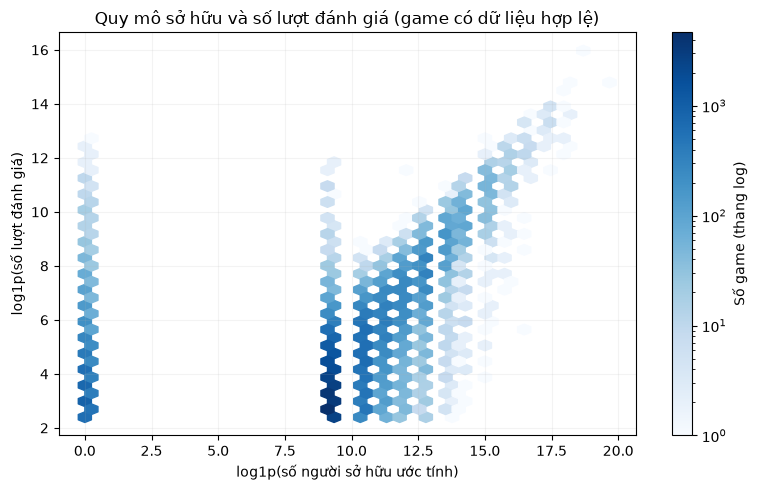

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
hexbin = ax.hexbin(log_owner_values, log_review_values, gridsize=40, mincnt=1, bins="log", cmap="Blues")
ax.set(title="Quy mô sở hữu và số lượt đánh giá (game có dữ liệu hợp lệ)", xlabel="log1p(số người sở hữu ước tính)", ylabel="log1p(số lượt đánh giá)")
fig.colorbar(hexbin, ax=ax, label="Số game (thang log)")
ax.grid(alpha=.15)
plt.tight_layout()

# Lưu hình ảnh vào thư mục báo cáo
for out_dir in ['reports/figures/q2', 'reports/figure/q2', 'report/figure/q2']:
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(out_dir) / 'figure1_owners_vs_reviews.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** Biểu đồ đi lên khá rõ: game có nhiều owner thường có nhiều lượt đánh giá hơn (Spearman ρ = 0,513). Tuy nhiên, các game có cùng quy mô owner vẫn có thể nhận số lượt đánh giá rất khác nhau. Điều đó cho thấy quy mô người sở hữu quan trọng, nhưng không phải yếu tố duy nhất quyết định việc người chơi để lại đánh giá. Vì hai trục dùng thang log, mỗi khoảng bằng nhau thể hiện mức tăng theo tỷ lệ; nhờ vậy có thể thấy cả game nhỏ lẫn game rất lớn. Biểu đồ không nói được rằng tăng owner sẽ tự động làm số lượt đánh giá tăng.

#### Trực quan hóa 2: Mối liên hệ theo thể loại

- **Mục tiêu:** So sánh ước lượng và KTC 95% của từng cờ thể loại trong mô hình.
- **Loại:** Biểu đồ điểm và thanh KTC 95%.

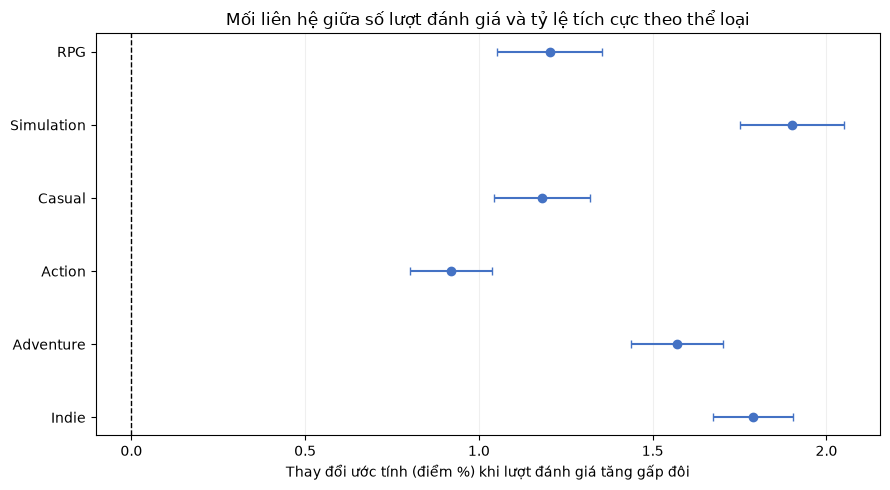

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = slope_all.reset_index()
centers = plot_data["Thay đổi tỷ lệ tích cực (điểm %) khi lượt đánh giá tăng gấp đôi, xấp xỉ"].to_numpy()
low = plot_data["KTC 95% dưới"].to_numpy()
high = plot_data["KTC 95% trên"].to_numpy()
y_pos = np.arange(len(plot_data))
ax.errorbar(centers, y_pos, xerr=[centers - low, high - centers], fmt="o", color="#4472C4", capsize=3)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(yticks=y_pos, yticklabels=plot_data["Thể loại"], title="Mối liên hệ giữa số lượt đánh giá và tỷ lệ tích cực theo thể loại", xlabel="Thay đổi ước tính (điểm %) khi lượt đánh giá tăng gấp đôi", ylabel="")
ax.grid(axis="x", alpha=.2)
plt.tight_layout()

# Lưu hình ảnh vào thư mục báo cáo
for out_dir in ['reports/figures/q2', 'reports/figure/q2', 'report/figure/q2']:
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(out_dir) / 'figure2_genre_slopes.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** Trong cả sáu cờ thể loại, khi số lượt đánh giá tăng gấp đôi thì tỷ lệ đánh giá tích cực ước tính chỉ tăng khoảng 0,9–1,9 điểm phần trăm. Ví dụ, nếu một game có tỷ lệ tích cực khoảng 80%, mức tăng này tương đương khoảng 81–82%, nên tác động ước tính là có nhưng không lớn. Thanh ngang là khoảng tin cậy 95%; chúng giúp thấy mức độ không chắc chắn của từng ước lượng. Kết quả đã xét owner và tuổi game, nhưng không chứng minh có thêm lượt đánh giá thì game sẽ được đánh giá tích cực hơn. Các thể loại có thể chồng lấn, vì vậy không nên dùng biểu đồ để xếp hạng hay khẳng định thể loại này khác thể loại kia.

### 7. Kết quả và thảo luận

**Mẫu phân tích:** 53.199/89.618 game có cả hai chỉ số đánh giá hợp lệ; 36.419 game có giá trị sentinel `-1` và không được đưa vào mô hình.

**Kết quả chính:** Sau khi xét tuổi game và sáu cờ thể loại, game có owner ước tính cao hơn thường có nhiều lượt đánh giá hơn. Cụ thể, owner tăng gấp đôi đi cùng khoảng 11,5% lượt đánh giá nhiều hơn; mỗi năm tuổi game tăng thêm đi cùng khoảng 4,3% lượt đánh giá nhiều hơn. Các khoảng tin cậy 95% của hai hệ số đều dương, nên xu hướng này ổn định trong mẫu phân tích.

**Theo thể loại:** Khi số lượt đánh giá tăng gấp đôi, tỷ lệ tích cực ước tính tăng khoảng 0,9–1,9 điểm phần trăm trong sáu nhóm được mô hình hóa. Kiểm định đồng thời các tương tác có p < 0,001, cho thấy mối liên hệ có liên quan đến các cờ thể loại trong mô hình. Kiểm định này không phải so sánh từng cặp thể loại.

**Độ bền:** Sau khi bỏ 1% game có nhiều lượt đánh giá nhất, hệ số quy mô sở hữu là 0,133 (0,128–0,139) và hệ số tuổi game là 0,046 (0,041–0,051). Dấu và độ lớn gần nhau, nên kết quả không chỉ do một số game rất lớn chi phối.

### 8. Kiểm tra độ bền vững

Để kiểm tra ảnh hưởng của các game có lượng đánh giá rất cao, mô hình được lặp lại sau khi loại bỏ 1% game ở nhóm cao nhất. Ngưỡng loại là 33.601 lượt đánh giá, mẫu còn lại có 52.670 game. Sau khi loại bỏ, kết quả không đổi đáng kể. Khi owner tăng gấp đôi, số lượt đánh giá tăng 11,5% ở mẫu đầy đủ và 9,6% sau khi loại ngoại lệ. Hệ số tuổi game thay nhẹ từ 0,0425 lên 0,0458. Cả hai quan hệ vẫn dương, cho thấy kết quả không bị một số ít game đông đánh giá làm lệch mạnh.

Với tỷ lệ đánh giá tích cực, kiểm định Wald vẫn rất có ý nghĩa sau khi loại ngoại lệ (`chi-square = 225,27`, `df = 6`, `p = 7,81e-46`). Các ước lượng theo thể loại cũng giữ hướng dương và ổn định. Vì vậy, kết luận chính vẫn bền: owner lớn và game lâu đời thường có nhiều đánh giá hơn, mức liên hệ giữa lượt đánh giá và tỷ lệ tích cực khác nhau theo thể loại.

### 9. Giới hạn phân tích

Dữ liệu là thống kê tổng hợp theo game. Khoảng 40,6% game không có chỉ số đánh giá hợp lệ nên không thể suy rộng kết quả cho nhóm này. `estimated_owners` là khoảng ước tính; các cột `positive`/`negative` không khớp `num_reviews_total` ở đa số game; và các thể loại có thể chồng lấn. Kiểm định tương tác hiện tại không tạo các so sánh cặp trực tiếp giữa thể loại.

### 10. Kết luận

**Trả lời RQ2:** Trong 53.199 game có dữ liệu đánh giá hợp lệ, game có owner lớn hơn và phát hành lâu hơn thường có nhiều lượt đánh giá hơn. Khi số lượt đánh giá tăng gấp đôi, tỷ lệ đánh giá tích cực chỉ tăng khoảng 0,9–1,9 điểm phần trăm trong các thể loại được mô hình hóa; đây là thay đổi nhỏ, không phải bằng chứng rằng nhiều đánh giá làm game được yêu thích hơn. Kết quả chính vẫn giữ khi bỏ 1% game có số lượt đánh giá cao nhất, nhưng không áp dụng cho 36.419 game thiếu chỉ số đánh giá hợp lệ và không thể hiện quan hệ nhân quả.